## Page Rank

In [1]:
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
G_u = nx.Graph()
G_u.add_nodes_from([0, 1, 2, 3])
G_u.add_edges_from([(0, 1), (0, 2), (1, 2), (2, 3)])

print("Node :", list(G_u.nodes()))
print("Edge :", list(G_u.edges()))

Node : [0, 1, 2, 3]
Edge : [(0, 1), (0, 2), (1, 2), (2, 3)]


In [3]:
G_d = nx.DiGraph()
G_d.add_nodes_from([0, 1, 2, 3])
G_d.add_edges_from([(0, 1), (0, 2), (1, 2), (2, 0), (3, 2)])

print("Node :", list(G_d.nodes()))
print("Edge :", list(G_d.edges()))

Node : [0, 1, 2, 3]
Edge : [(0, 1), (0, 2), (1, 2), (2, 0), (3, 2)]


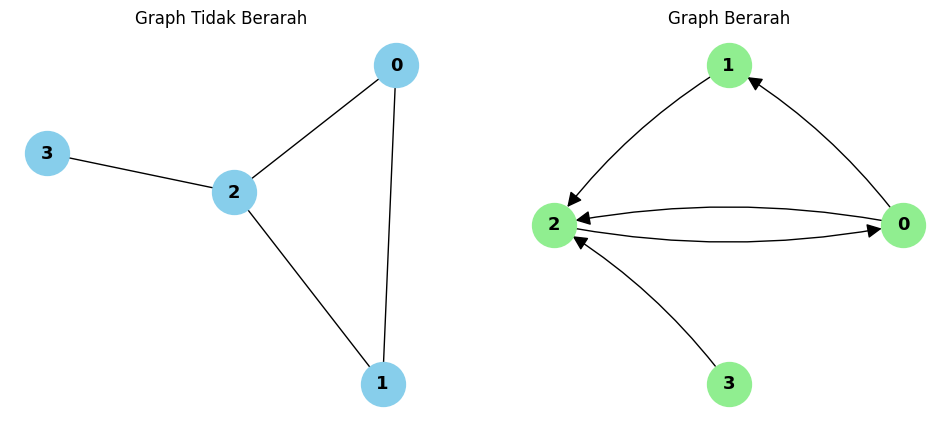

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

pos_u = nx.spring_layout(G_u, seed=42)
nx.draw(G_u, pos_u, ax=ax[0], with_labels=True, node_color="skyblue",
        node_size=1000, font_size=13, font_weight="bold")
ax[0].set_title("Graph Tidak Berarah")

pos_d = nx.circular_layout(G_d)
nx.draw(G_d, pos_d, ax=ax[1], with_labels=True, node_color="lightgreen",
        node_size=1000, font_size=13, font_weight="bold",
        arrows=True, arrowsize=22, connectionstyle="arc3,rad=0.1")
ax[1].set_title("Graph Berarah")

plt.show()

In [5]:
nodes = sorted(G_u.nodes())

adj_u = pd.DataFrame(nx.to_numpy_array(G_u, nodelist=nodes, dtype=int),
                     index=nodes, columns=nodes)
adj_d = pd.DataFrame(nx.to_numpy_array(G_d, nodelist=nodes, dtype=int),
                     index=nodes, columns=nodes)

print("Matriks Adjacency - Tidak Berarah")
display(adj_u)
print("\nMatriks Adjacency - Berarah (baris = asal, kolom = tujuan)")
display(adj_d)

Matriks Adjacency - Tidak Berarah


,0,1,2,3
0,0,1,1,0
1,1,0,1,0
2,1,1,0,1
3,0,0,1,0



Matriks Adjacency - Berarah (baris = asal, kolom = tujuan)


,0,1,2,3
0,0,1,1,0
1,0,0,1,0
2,1,0,0,0
3,0,0,1,0


In [6]:
def transition_matrix(G):
    A = nx.to_numpy_array(G, nodelist=sorted(G.nodes()))
    row_sum = A.sum(axis=1, keepdims=True)
    return A / row_sum   # aman karena tidak ada node tanpa edge keluar

P_u = pd.DataFrame(transition_matrix(G_u), index=nodes, columns=nodes)
P_d = pd.DataFrame(transition_matrix(G_d), index=nodes, columns=nodes)

print("Matriks Transisi - Tidak Berarah")
display(P_u.round(4))
print("\nMatriks Transisi - Berarah")
display(P_d.round(4))

Matriks Transisi - Tidak Berarah


,0,1,2,3
0,0.0000,0.5000,0.5,0.0000
1,0.5000,0.0000,0.5,0.0000
2,0.3333,0.3333,0.0,0.3333
3,0.0000,0.0000,1.0,0.0000



Matriks Transisi - Berarah


,0,1,2,3
0,0.0,0.5,0.5,0.0
1,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0
3,0.0,0.0,1.0,0.0


In [7]:
alpha = 0.85   # damping factor

pr_u = nx.pagerank(G_u, alpha=alpha)
pr_d = nx.pagerank(G_d, alpha=alpha)

df_pr = pd.DataFrame({
    "PageRank Undirected": pr_u,
    "PageRank Directed": pr_d
})
df_pr.index.name = "Node"

display(df_pr.round(4))
print("Total Undirected :", round(sum(pr_u.values()), 4))
print("Total Directed   :", round(sum(pr_d.values()), 4))

,PageRank Undirected,PageRank Directed
Node,,
0,0.2459,0.3725
1,0.2459,0.1958
2,0.3667,0.3942
3,0.1414,0.0375


Total Undirected : 1.0
Total Directed   : 1.0


In [8]:
top_u = max(pr_u, key=pr_u.get)
top_d = max(pr_d, key=pr_d.get)

print(f"Undirected : node {top_u} paling tinggi (PageRank = {pr_u[top_u]:.4f})")
print(f"Directed   : node {top_d} paling tinggi (PageRank = {pr_d[top_d]:.4f})")

print("\nPeringkat Undirected:")
for r, (n, v) in enumerate(sorted(pr_u.items(), key=lambda x: -x[1]), 1):
    print(f"  {r}. Node {n} -> {v:.4f}")

print("\nPeringkat Directed:")
for r, (n, v) in enumerate(sorted(pr_d.items(), key=lambda x: -x[1]), 1):
    print(f"  {r}. Node {n} -> {v:.4f}")

Undirected : node 2 paling tinggi (PageRank = 0.3667)
Directed   : node 2 paling tinggi (PageRank = 0.3942)

Peringkat Undirected:
  1. Node 2 -> 0.3667
  2. Node 0 -> 0.2459
  3. Node 1 -> 0.2459
  4. Node 3 -> 0.1414

Peringkat Directed:
  1. Node 2 -> 0.3942
  2. Node 0 -> 0.3725
  3. Node 1 -> 0.1958
  4. Node 3 -> 0.0375


In [9]:
top_u = max(pr_u, key=pr_u.get)
top_d = max(pr_d, key=pr_d.get)

print(f"Undirected : node {top_u} paling tinggi (PageRank = {pr_u[top_u]:.4f})")
print(f"Directed   : node {top_d} paling tinggi (PageRank = {pr_d[top_d]:.4f})")

print("\nPeringkat Undirected:")
for r, (n, v) in enumerate(sorted(pr_u.items(), key=lambda x: -x[1]), 1):
    print(f"  {r}. Node {n} -> {v:.4f}")

print("\nPeringkat Directed:")
for r, (n, v) in enumerate(sorted(pr_d.items(), key=lambda x: -x[1]), 1):
    print(f"  {r}. Node {n} -> {v:.4f}")

Undirected : node 2 paling tinggi (PageRank = 0.3667)
Directed   : node 2 paling tinggi (PageRank = 0.3942)

Peringkat Undirected:
  1. Node 2 -> 0.3667
  2. Node 0 -> 0.2459
  3. Node 1 -> 0.2459
  4. Node 3 -> 0.1414

Peringkat Directed:
  1. Node 2 -> 0.3942
  2. Node 0 -> 0.3725
  3. Node 1 -> 0.1958
  4. Node 3 -> 0.0375


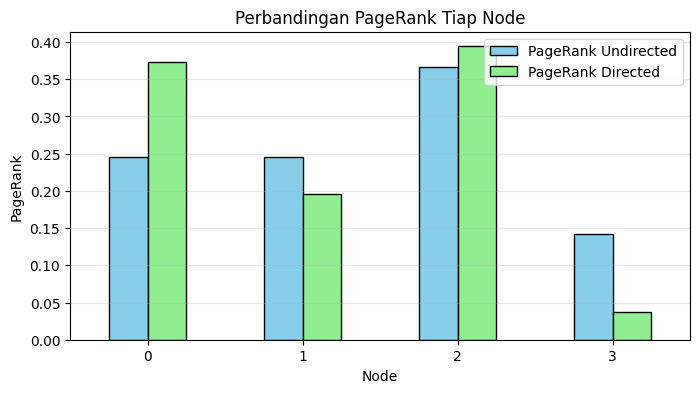

In [ ]:
df_pr.plot(kind="bar", figsize=(8, 4), color=["skyblue", "lightgreen"],
           edgecolor="black")
plt.title("Perbandingan PageRank Tiap Node")
plt.xlabel("Node")
plt.ylabel("PageRank")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

In [15]:
def pagerank_manual(P, alpha=0.85, tol=1e-10, max_iter=1000):
    n = P.shape[0]
    G_mat = alpha * P + (1 - alpha) / n     # matriks Google
    r = np.ones(n) / n
    for _ in range(max_iter):
        r_new = r @ G_mat
        if np.abs(r_new - r).sum() < tol:
            break
        r = r_new
    return r_new

manual_u = pagerank_manual(P_u.values)
manual_d = pagerank_manual(P_d.values)

df_check = pd.DataFrame({
    "NetworkX Undirected": [pr_u[n] for n in nodes],
    "Manual Undirected": manual_u,
    "NetworkX Directed": [pr_d[n] for n in nodes],
    "Manual Directed": manual_d,
}, index=nodes)
df_check.index.name = "Node"

display(df_check.round(4))

,NetworkX Undirected,Manual Undirected,NetworkX Directed,Manual Directed
Node,,,,
0,0.2459,0.2459,0.3725,0.3725
1,0.2459,0.2459,0.1958,0.1958
2,0.3667,0.3667,0.3942,0.3941
3,0.1414,0.1414,0.0375,0.0375


In [16]:
alphas = [0.5, 0.7, 0.85, 0.95]
rows = []
for a in alphas:
    p = nx.pagerank(G_d, alpha=a)
    rows.append({"alpha": a, **{f"Node {n}": round(v, 4) for n, v in p.items()}})

display(pd.DataFrame(rows).set_index("alpha"))

,Node 0,Node 1,Node 2,Node 3
alpha,,,,
0.50,0.3077,0.2019,0.3654,0.1250
0.70,0.3445,0.1956,0.3850,0.0750
0.85,0.3725,0.1958,0.3942,0.0375
0.95,0.3909,0.1982,0.3984,0.0125
